SMB缺失数:0
albedo_summer缺失数:0
SMB 皮尔逊相关:0.5839
SMB 斯皮尔曼相关:0.5092
SMB 互信息:0.7909
回归模型: albedo_summer = 0.0000 * SMB + 0.7115
R^2 = 0.3410


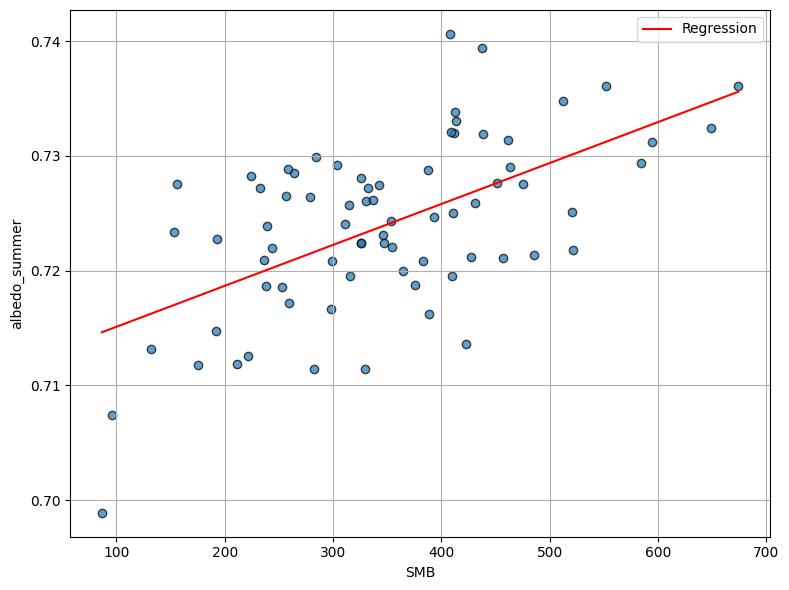

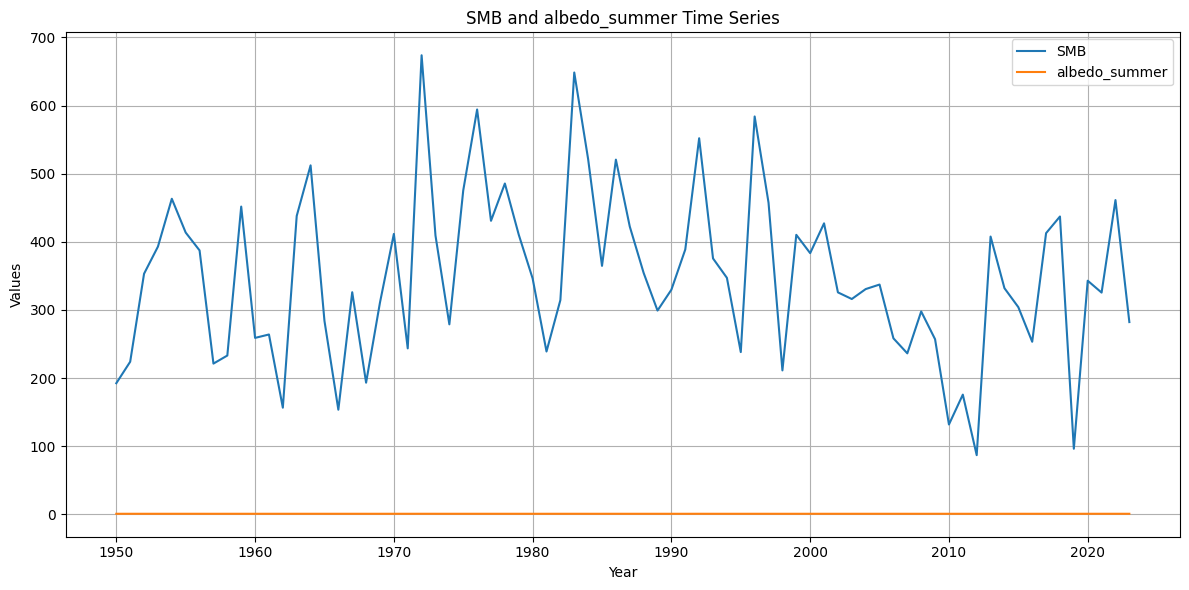

Granger因果检测:
{1: ({'ssr_ftest': (0.6487147979839624, 0.42330005866714737, 70.0, 1), 'ssr_chi2test': (0.6765168607547036, 0.41078871709717657, 1), 'lrtest': (0.6734013337197666, 0.41186825481295153, 1), 'params_ftest': (0.648714798043028, 0.4233000586461343, 70.0, 1.0)}, [<statsmodels.regression.linear_model.RegressionResultsWrapper object at 0x0000027932539D10>, <statsmodels.regression.linear_model.RegressionResultsWrapper object at 0x000002793252F990>, array([[0., 1., 0.]])]), 2: ({'ssr_ftest': (0.8682029212766806, 0.42437269697047497, 67.0, 2), 'ssr_chi2test': (1.8659883681170448, 0.3933741107921763, 2), 'lrtest': (1.8422182371386953, 0.3980772812431161, 2), 'params_ftest': (0.8682029212754613, 0.42437269697098023, 67.0, 2.0)}, [<statsmodels.regression.linear_model.RegressionResultsWrapper object at 0x00000279324CA290>, <statsmodels.regression.linear_model.RegressionResultsWrapper object at 0x0000027932561310>, array([[0., 0., 1., 0., 0.],
       [0., 0., 0., 1., 0.]])]), 3: ({'ssr_f

E:\anaconda3\Lib\site-packages\statsmodels\tsa\stattools.py:1488: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(


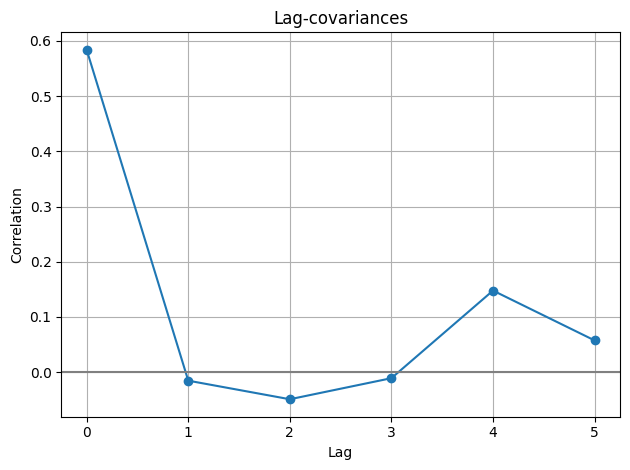

In [4]:
# ====================
# 导入库  回归模型-----------albedo_summer 和冰盖表面质量SMB------------相关性分析-------------------------------
# ====================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mutual_info_score
from scipy.stats import linregress
from statsmodels.tsa.stattools import grangercausalitytests

# ====================
# 函数封裝
# ====================

def compute_correlations(x, y):
    """
    计算皮尔逊、斯皮尔曼和互信息。
    """
    pearson = x.corr(y, method='pearson')
    spearman = x.corr(y, method='spearman')
    # 互信息需要离桶后再算
    x_bins = pd.qcut(x, q=10, duplicates='drop').cat.codes
    y_bins = pd.qcut(y, q=10, duplicates='drop').cat.codes
    mutual = mutual_info_score(x_bins, y_bins)
    return pearson, spearman, mutual


def plot_scatter_regression(x, y, x_label='X', y_label='Y'):
    """
     scatter plot + regression
    """
    slope, intercept, r_value, p_value, std_err = linregress(x, y)
    print(f'回归模型: {y_label} = {slope:.4f} * {x_label} + {intercept:.4f}')
    print(f'R^2 = {r_value**2:.4f}')

    plt.figure(figsize=(8, 6))
    plt.scatter(x, y, alpha=0.7, edgecolors='k')
    plt.plot(np.linspace(x.min(), x.max(), 100), 
              slope * np.linspace(x.min(), x.max(), 100) + intercept, color='red', label='Regression')
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


def plot_time_series(t, x, y, label1='X', label2='Y'):
    """
    时间序列对比
    """
    plt.figure(figsize=(12,6))
    plt.plot(t, x, label=label1)
    plt.plot(t, y, label=label2)
    plt.xlabel('Year')
    plt.ylabel('Values')
    plt.title(f'{label1} and {label2} Time Series')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


def compute_lag_correlation(x, y, max_lag=5):
    """
    计算时滞相关
    """
    lag_vals = range(0, max_lag+1)
    corr_vals = []
    for lag in lag_vals:
        corr_vals.append(x.corr(y.shift(lag)))
    return lag_vals, corr_vals


def plot_lag_correlation(lags, corrs):
    """
    时滞相关可视化
    """
    plt.figure()
    plt.plot(lags, corrs, marker='o')
    plt.axhline(0, color='grey')
    plt.xlabel('Lag')
    plt.ylabel('Correlation')
    plt.title('Lag-covariances')
    plt.grid(True)
    plt.tight_layout()
    plt.show()


def granger_causality(x, y, maxlag=5):
    """
    Granger因果检测：
    检验 x 是否 Granger导致 y
    """
    df = pd.concat([y, x], axis=1)
    result = grangercausalitytests(df, maxlag=maxlag, verbose=False)
    return result


# ====================
# main
# ====================

def main(filename, col1, col2, max_lag=5):
    """
    :paramfilename: CSV 文件
    :param col1: 需要分析的列1
    :param col2: 需要分析的列2
    """
    df = pd.read_csv(filename)
    df = df[(df['time'] >= 1950) & (df['time'] <= 2023)].copy()

    # 检查缺失
    print(f'{col1}缺失数:{df[col1].isnull().sum()}')
    print(f'{col2}缺失数:{df[col2].isnull().sum()}')

    # 相关性
    pearson, spearman, mutual = compute_correlations(
        df[col1], df[col2]
    )
    print(f'{col1} 皮尔逊相关:{pearson:.4f}')
    print(f'{col1} 斯皮尔曼相关:{spearman:.4f}')
    print(f'{col1} 互信息:{mutual:.4f}')

    # 单变量回归量化
    plot_scatter_regression(
        df[col1],
        df[col2],
        x_label=col1,
        y_label=col2
    )

    # 时间序列对比
    plot_time_series(
        df['time'], 
        df[col1],
        df[col2],
        label1=col1,
        label2=col2
    )

    # Granger因果检测
    print("Granger因果检测:")
    result = granger_causality(
        df[col1],
        df[col2],
        maxlag=max_lag
    )
    print(result)

    #时滞相关
    lags, corrs = compute_lag_correlation(
        df[col1],
        df[col2],
        max_lag=max_lag
    )
    print("时滞相关:")
    for lag, corr in zip(lags, corrs):
        print(f'lag {lag} -> corr {corr}')

    plot_lag_correlation(lags, corrs)


if __name__ == "__main__":
    # 你可以修改为你自己的列：
    main(filename=r'E:\TUB\greenland\MB_SMB_D_BMB_ann.csv',
          col1='SMB',
          col2='albedo_summer',
          max_lag=5)


共找到9个shp文件


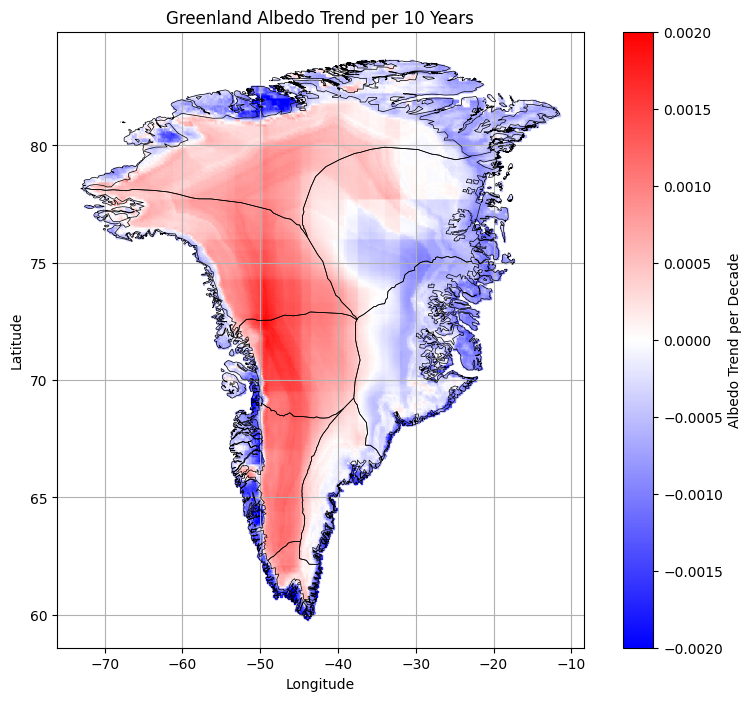

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import geopandas as gpd
import glob
import os

# 1. 检查shp文件数
shp_dir = r'E:\TUB\greenland\Greenland_shp\流域冰盖'
shp_files = glob.glob(os.path.join(shp_dir, "*.shp"))

if len(shp_files) == 9:
    print("共找到9个shp文件")
else:
    print(f"警告：共找到{len(shp_files)}个shp文件，其中不足9个")

# 2. 读数据
file_path = r"F:\TUB\greenlandProject\ERA5LAND\MonthlyFeatures\1995prediction\Greenland_albedo_trend_results.csv"
df = pd.read_csv(file_path)

# 3. 渲染时设置渲染样式
norm = mcolors.TwoSlopeNorm(vmin=-0.002, vcenter=0, vmax=0.002)

# 4. 画 scatter
plt.figure(figsize=(10, 8))
sc = plt.scatter(
    df['longitude'], df['latitude'],
    c=df['slope_per_decade'],
    cmap='bwr',
    norm=norm,
    marker='s',
    s=1,
    alpha=1.0
)

plt.colorbar(sc, label='Albedo Trend per Decade')
plt.title('Greenland Albedo Trend per 10 Years')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True)
plt.gca().set_facecolor('white')

# 5. 渲染每一个shp文件为边界线
for shp_file in shp_files:
    gdf = gpd.read_file(shp_file)
    gdf.boundary.plot(ax=plt.gca(), color='black', linewidth=0.5)

# 6. 显示最终渲染出的图片
plt.show()


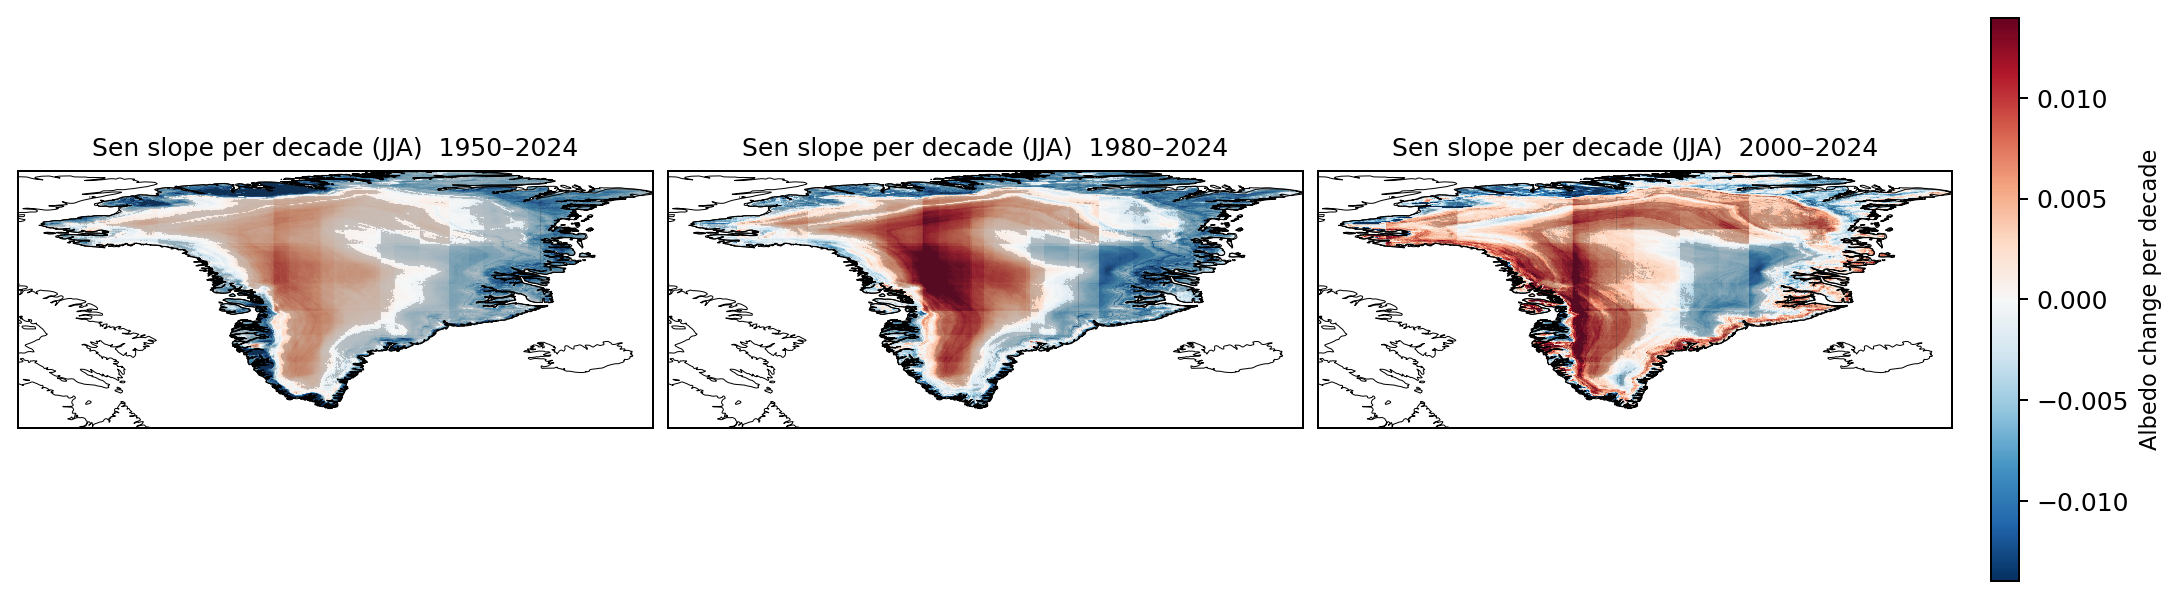

已保存： C:\greenland\NosdePrediction\trend_maps_3panels.png


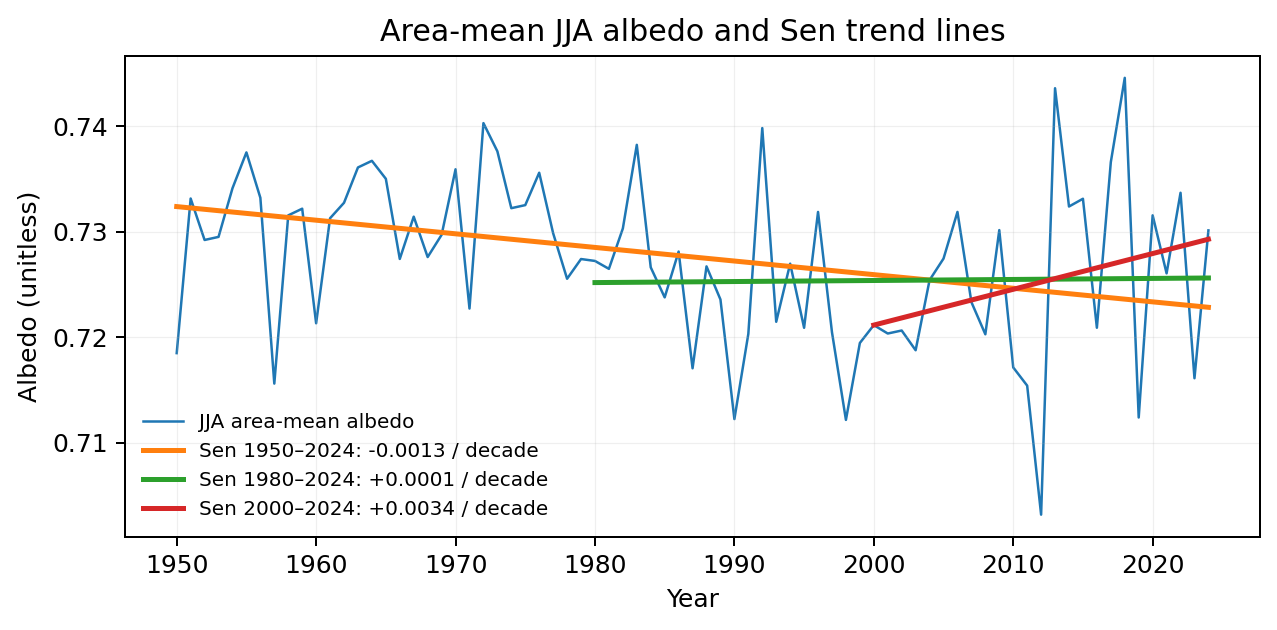

已保存： C:\greenland\NosdePrediction\area_mean_JJA_with_Sen_lines.png


In [3]:
# -*- coding: utf-8 -*-
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import cartopy.crs as ccrs
from cartopy.io.shapereader import Reader
from scipy.stats import theilslopes, kendalltau, norm

# ====== 配置 ======
NC_PATH  = r"C:\greenland\NosdePrediction\greenlandNoSde_clip.nc"
SHP_PATH = r"C:\greenland\Greenland_shp\Gboundry.shp"
OUT_DIR  = r"C:\greenland\NosdePrediction"
VAR_NAME = "albedo"
SEASON_MONTHS = [6,7,8]     # JJA；想用全年就改为 None
Z_THRESHOLD = 1.96          # 95% 显著性
MIN_YEARS = 20              # 最少年份

# ====== 工具函数 ======
def sen_slope_and_mkZ(y, x):
    """一维序列 Sen 斜率（每年）与 MK Z（双侧）"""
    y = np.asarray(y, float)
    x = np.asarray(x, float)
    m = np.isfinite(y)
    if m.sum() < MIN_YEARS:
        return np.nan, np.nan
    yy = y[m]; xx = x[m]
    try:
        slope, _, _, _ = theilslopes(yy, xx, 0.95)
    except Exception:
        slope = np.nan
    try:
        _, p = kendalltau(xx, yy, nan_policy="omit")
        Z = norm.ppf(1 - p/2) if p is not None and np.isfinite(p) else np.nan
    except Exception:
        Z = np.nan
    return slope, Z

def compute_trend_map(A, years):
    """对 (year, lat, lon) 的年均数组做 Sen + MK，返回每十年斜率、Z"""
    Ay = A.sel(year=slice(years[0], years[-1]))
    Y = Ay['year'].values.astype(int)
    Ay2 = Ay.stack(points=('lat','lon')).transpose('year','points').values
    ny, npts = Ay2.shape
    slopes = np.full(npts, np.nan, float)
    Zvals  = np.full(npts, np.nan, float)
    for i in range(npts):
        s, z = sen_slope_and_mkZ(Ay2[:, i], Y)
        slopes[i] = s
        Zvals[i]  = z
    sl2d = xr.DataArray(slopes.reshape((Ay.sizes['lat'], Ay.sizes['lon'])),
                        coords={'lat':Ay['lat'], 'lon':Ay['lon']}, dims=('lat','lon'))
    Z2d  = xr.DataArray(Zvals.reshape((Ay.sizes['lat'], Ay.sizes['lon'])),
                        coords={'lat':Ay['lat'], 'lon':Ay['lon']}, dims=('lat','lon'))
    return sl2d*10.0, Z2d  # 每十年

def plot_trend(ax, slope_decade, Z2d, title, shp_path=None):
    proj = ccrs.PlateCarree()
    lon = slope_decade['lon'].values; lat = slope_decade['lat'].values
    xx, yy = np.meshgrid(lon, lat)
    # 鲁棒色阶
    vmax = np.nanpercentile(np.abs(slope_decade.values), 98)
    vmax = 0.05 if not np.isfinite(vmax) or vmax==0 else vmax  # 防止全NaN
    norm = TwoSlopeNorm(vcenter=0.0, vmin=-vmax, vmax=vmax)
    im = ax.pcolormesh(xx, yy, slope_decade.values, transform=proj,
                       cmap='RdBu_r', norm=norm, rasterized=True)
    # 很不明显的显著性点：极小+高透明
    sig = (Z2d.values > Z_THRESHOLD) & np.isfinite(slope_decade.values)
    if sig.any():
        iy, ix = np.where(sig)
        ax.scatter(xx[iy, ix], yy[iy, ix], s=0.2, c='0.2', alpha=0.25,
                   marker='o', transform=proj, zorder=3, linewidths=0)
    # 边界
    if shp_path:
        try:
            ax.add_geometries(list(Reader(shp_path).geometries()), proj,
                              facecolor='none', edgecolor='k', linewidth=0.4, zorder=4)
        except Exception as e:
            print(f"边界绘制失败: {e}")
    ax.set_title(title, fontsize=10)
    ax.coastlines(resolution='50m', linewidth=0.4)
    return im, norm

def add_colorbar(fig, im, label="Albedo change per decade"):
    cb = fig.colorbar(im, ax=fig.axes, shrink=0.82, pad=0.02)
    cb.set_label(label, fontsize=9)

def area_mean_series(Ay):
    """对 (year, lat, lon) 年均求全域平均（忽略 NaN）"""
    ts = Ay.mean(dim=('lat','lon'), skipna=True)
    return ts['year'].values.astype(int), ts.values

def fit_sen_line(x, y, x0, x1):
    """在区间 [x0,x1] 上拟合 Sen 线并返回 (x_plot, y_plot, slope_per_decade)"""
    m = (x>=x0) & (x<=x1) & np.isfinite(y)
    if m.sum() < MIN_YEARS:
        return None, None, np.nan
    s, _ = sen_slope_and_mkZ(y[m], x[m])
    xseg = np.array([x0, x1], int)
    # 用中位截距近似：y - s*x 的中位数
    b = np.median(y[m] - s*x[m])
    yseg = s*xseg + b
    return xseg, yseg, s*10.0  # 每十年

# ====== 读取并做年聚合（JJA 或全年）======
ds = xr.open_dataset(NC_PATH)
A = ds[VAR_NAME]
if SEASON_MONTHS is not None:
    A = A.where(A['time'].dt.month.isin(SEASON_MONTHS), drop=True)
Ay = A.groupby('time.year').mean('time')  # (year, lat, lon)
all_years = Ay['year'].values.astype(int)
ystart, yend = int(all_years.min()), int(all_years.max())

# ====== 三个时段的空间趋势图 ======
periods = [(1950, yend), (1980, yend), (2000, yend)]
titles = [f"Sen slope per decade (JJA)  {p[0]}–{p[1]}" for p in periods]
outs   = [fr"{OUT_DIR}\trend_map_{p[0]}-{p[1]}.png" for p in periods]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.9),
                         subplot_kw={'projection': ccrs.PlateCarree()},
                         constrained_layout=True, dpi=180)
first_im = None
for ax, (y0,y1), ttl in zip(axes, periods, titles):
    slope_dec, Z2d = compute_trend_map(Ay, np.arange(y0, y1+1))
    im, _ = plot_trend(ax, slope_dec, Z2d, ttl, shp_path=SHP_PATH)
    if first_im is None:
        first_im = im
# 统一色标
add_colorbar(fig, first_im, "Albedo change per decade")
fig.savefig(fr"{OUT_DIR}\trend_maps_3panels.png", dpi=300)
plt.show()
print("已保存：", fr"{OUT_DIR}\trend_maps_3panels.png")

# ====== 整体时间序列 + 三段 Sen 线 ======
x, y = area_mean_series(Ay)  # 年序列（全域均值）
fig2 = plt.figure(figsize=(7.2, 3.6), dpi=180)
plt.plot(x, y, '-', lw=1.0, label='JJA area-mean albedo', zorder=1)

seg_info = []
for (x0,x1), name, color in zip(periods, ['1950–2024','1980–2024','2000–2024'],
                                ['C1','C2','C3']):
    xseg, yseg, s_dec = fit_sen_line(x, y, x0, x1)
    if xseg is not None:
        plt.plot(xseg, yseg, '-', lw=2.0, color=color,
                 label=f"Sen {name}: {s_dec:+.4f} / decade", zorder=3)

plt.xlabel("Year"); plt.ylabel("Albedo (unitless)")
plt.title("Area-mean JJA albedo and Sen trend lines")
plt.grid(alpha=0.2, lw=0.5)
plt.legend(fontsize=8, frameon=False, ncol=1)
out_ts = fr"{OUT_DIR}\area_mean_JJA_with_Sen_lines.png"
plt.tight_layout(); plt.savefig(out_ts, dpi=300); plt.show()
print("已保存：", out_ts)


In [ ]:
#提取-----------气象站albedo（真值）和模型生成model_albedo------放到一个表里--1950-2024,4-9yue-
import os
import pandas as pd
import numpy as np
from scipy.spatial import cKDTree

# 路径配置
station_csv = r"F:\TUB\greenlandProject\ERA5LAND\merged_allfeature.csv"
model_base_dir = r"F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenlandAlbedo"
model_folder = "1995bu"  # 所有模型文件都在这个文件夹，不管年份

output_path = os.path.join(model_base_dir, model_folder, "model&station.csv")

# 读取气象站数据
df_station = pd.read_csv(station_csv)

# 检查是否有经纬度列
if not {'latitude', 'longitude'}.issubset(df_station.columns):
    raise ValueError("气象站数据缺少 latitude 或 longitude 列")

results = []
model_data_cache = {}  # 缓存模型文件数据，避免重复读文件

for idx, row in df_station.iterrows():
    year = int(row['year'])
    month = int(row['month'])
    station = row['station']
    albedo_obs = row['albedo']
    lat_sta = row['latitude']
    lon_sta = row['longitude']

    # 构造模型文件名，不管年份，都在同一文件夹
    file_name = f"{year}{month:02d}GMonthlyalbedo.csv"
    model_file_path = os.path.join(model_base_dir, model_folder, file_name)

    # 读模型数据，缓存
    if model_file_path in model_data_cache:
        df_model = model_data_cache[model_file_path]
    else:
        if not os.path.exists(model_file_path):
            print(f"警告: 模型文件不存在: {model_file_path}，跳过 {year}-{month} {station}")
            continue
        df_model = pd.read_csv(model_file_path)
        # 确认列存在
        if not {'latitude', 'longitude', 'albedo'}.issubset(df_model.columns):
            print(f"警告: 模型文件列不完整: {model_file_path}，跳过 {year}-{month} {station}")
            continue
        model_data_cache[model_file_path] = df_model

    # 构建模型点的坐标数组
    model_coords = df_model[['latitude', 'longitude']].values
    tree = cKDTree(model_coords)

    # 查询最近邻
    dist, idx_nn = tree.query([lat_sta, lon_sta], k=1)
    if np.isnan(dist):
        print(f"警告: 找不到最近邻插值 {year}-{month} {station} albedo_obs={albedo_obs}")
        continue

    model_albedo = df_model.iloc[idx_nn]['albedo']
    model_lat = df_model.iloc[idx_nn]['latitude']
    model_lon = df_model.iloc[idx_nn]['longitude']

    results.append({
        'year': year,
        'month': month,
        'station': station,
        'albedo': albedo_obs,
        'latitude': lat_sta,
        'longitude': lon_sta,
        'model_albedo': model_albedo,
        'model_latitude': model_lat,
        'model_longitude': model_lon
    })

# 结果保存
df_result = pd.DataFrame(results)
os.makedirs(os.path.dirname(output_path), exist_ok=True)
df_result.to_csv(output_path, index=False)
print(f"结果已保存到 {output_path}")


In [ ]:
---------------------------以下为----------------------
---------------------------回归模型-----------全部albedo_summer 和站点albedo-----------相关性分析----------------真值校验模型---------------
---------------------------每个站点做模型值校验-----------------------
---------------------------分站点类型-------------------------bias分析
× 没必要做，数据泄露，只用没有训练模型的数据做验证 ×



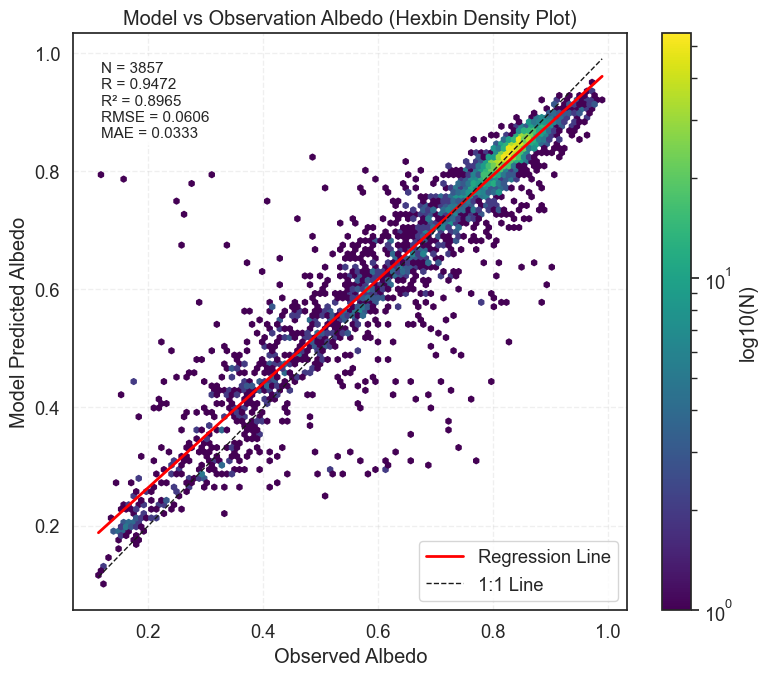

In [12]:
#回归模型-----------albedo_summer 和站点albedo-----------相关性分析----------------真值校验模型---------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import linregress, pearsonr

# 文件路径
csv_path = r"F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenlandAlbedo\1995bu\model&station.csv"

# 读取数据
df = pd.read_csv(csv_path)
df = df.dropna(subset=['albedo', 'model_albedo'])

# 提取真值与预测
y_true = df['albedo'].values
y_pred = df['model_albedo'].values

# 计算统计量
r, _ = pearsonr(y_true, y_pred)
r2 = r2_score(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae = mean_absolute_error(y_true, y_pred)
n = len(y_true)

# 拟合回归线
slope, intercept, _, _, _ = linregress(y_true, y_pred)
x_vals = np.linspace(min(y_true), max(y_true), 100)
reg_line = slope * x_vals + intercept

# 图像设置
plt.figure(figsize=(8, 7))
plt.hexbin(y_true, y_pred, gridsize=100, cmap='viridis', bins='log', mincnt=1)

# 添加回归线（红色）和 1:1 线（黑虚线）
plt.plot(x_vals, reg_line, color='red', lw=2, label='Regression Line')
plt.plot(x_vals, x_vals, 'k--', lw=1, label='1:1 Line')

# 统计文本框
textstr = '\n'.join([
    f'N = {n}',
    f'R = {r:.4f}',
    f'R² = {r2:.4f}',
    f'RMSE = {rmse:.4f}',
    f'MAE = {mae:.4f}'
])
plt.text(0.05, 0.95, textstr, transform=plt.gca().transAxes,
         fontsize=11, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

# 图形美化
plt.xlabel('Observed Albedo')
plt.ylabel('Model Predicted Albedo')
plt.title('Model vs Observation Albedo (Hexbin Density Plot)')
plt.colorbar(label='log10(N)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()

# 保存（如有需要）
# plt.savefig("F:/your_path/model_vs_obs_hexbin.png", dpi=300)

# 显示图像
plt.show()


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import linregress, pearsonr
import os

# 数据路径
csv_path = r"F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenlandAlbedo\1995bu\model&station.csv"
output_dir = r"F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenlandAlbedo\1995bu\station_plots"
os.makedirs(output_dir, exist_ok=True)

# 读取数据
df = pd.read_csv(csv_path)
df = df.dropna(subset=['albedo', 'model_albedo'])

# 获取所有唯一站点
stations = df['station'].unique()

for station in stations:
    df_sta = df[df['station'] == station]

    # 过滤后可能为空
    if len(df_sta) < 5:
        print(f"跳过 {station}，数据点太少: {len(df_sta)}")
        continue

    y_true = df_sta['albedo'].values
    y_pred = df_sta['model_albedo'].values

    # 统计量
    r, _ = pearsonr(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    n = len(y_true)

    # 回归线
    slope, intercept, _, _, _ = linregress(y_true, y_pred)
    x_vals = np.linspace(min(y_true), max(y_true), 100)
    reg_line = slope * x_vals + intercept

    # 画图
    plt.figure(figsize=(8, 7))
    plt.hexbin(y_true, y_pred, gridsize=60, cmap='viridis', bins='log', mincnt=1)

    # 回归线和1:1线
    plt.plot(x_vals, reg_line, color='red', lw=2, label='Regression Line')
    plt.plot(x_vals, x_vals, 'k--', lw=1, label='1:1 Line')

    # 统计框
    textstr = '\n'.join([
        f'N = {n}',
        f'R = {r:.4f}',
        f'R² = {r2:.4f}',
        f'RMSE = {rmse:.4f}',
        f'MAE = {mae:.4f}'
    ])
    plt.text(0.05, 0.95, textstr, transform=plt.gca().transAxes,
             fontsize=11, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

    # 美化
    plt.xlabel('Observed Albedo')
    plt.ylabel('Model Predicted Albedo')
    plt.title(f'Model vs Observation Albedo ({station})')
    plt.colorbar(label='log10(N)')
    plt.legend(loc='lower right')
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()

    # 保存图像
    out_path = os.path.join(output_dir, f"{station}_model_vs_obs.png")
    plt.savefig(out_path, dpi=300)
    plt.close()

    print(f"✅ 图已保存: {out_path}")


✅ 图已保存: F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenlandAlbedo\1995bu\station_plots\CEN_model_vs_obs.png
✅ 图已保存: F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenlandAlbedo\1995bu\station_plots\CP1_model_vs_obs.png
✅ 图已保存: F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenlandAlbedo\1995bu\station_plots\DY2_model_vs_obs.png
✅ 图已保存: F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenlandAlbedo\1995bu\station_plots\EGP_model_vs_obs.png
✅ 图已保存: F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenlandAlbedo\1995bu\station_plots\FRE_model_vs_obs.png
✅ 图已保存: F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenlandAlbedo\1995bu\station_plots\HUM_model_vs_obs.png
✅ 图已保存: F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenlandAlbedo\1995bu\station_plots\JAR_model_vs_obs.png
✅ 图已保存: F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenlandAlbedo\1995bu\station_plots\KAN_B_model_vs_obs.png
✅ 图已保存: F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenlandAlbedo\1995b

Type类别分布：
type
ice sheet        3543
local glacier     225
tundra             89
Name: count, dtype: int64


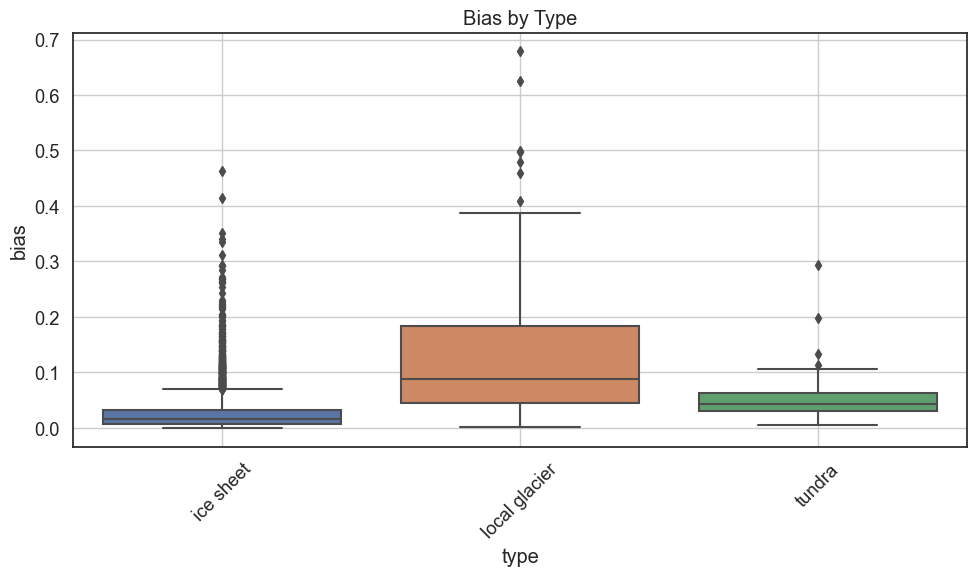

ANOVA 检验结果：
F值: 487.5157, p值: 0.0000

回归方差分析（OLS）结果：
            sum_sq      df           F         PR(>F)
C(type)   2.000297     2.0  487.515691  1.793050e-189
Residual  7.906559  3854.0         NaN            NaN

各类别平均 bias：
type
ice sheet        0.027130
local glacier    0.123673
tundra           0.050965
Name: bias, dtype: float64


In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import f_oneway

# 读取数据
file_path = r"F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenlandAlbedo\1995bu\model&station_distance_with_type.csv"
df = pd.read_csv(file_path)

# 去除缺失
df = df.dropna(subset=['bias', 'type'])

# 显示不同类别数量
print("Type类别分布：")
print(df['type'].value_counts())

# ===== 可视化 bias 在各类 type 下的分布 =====
plt.figure(figsize=(10, 6))
sns.boxplot(x='type', y='bias', data=df)
plt.xticks(rotation=45)
plt.title('Bias by Type')
plt.tight_layout()
plt.grid(True)
plt.show()

# ===== 方差分析 ANOVA =====
groups = [group['bias'].values for name, group in df.groupby('type')]
f_stat, p_val = f_oneway(*groups)
print("ANOVA 检验结果：")
print(f"F值: {f_stat:.4f}, p值: {p_val:.4f}")

# ===== 用回归方式进一步建模 =====
model = smf.ols('bias ~ C(type)', data=df).fit()
anova_table = sm.stats.anova_lm(model, typ=2)

print("\n回归方差分析（OLS）结果：")
print(anova_table)

# 可选：输出每个type的平均bias
print("\n各类别平均 bias：")
print(df.groupby("type")["bias"].mean())
